# Sintesi automatica di cartelle cliniche con Huggingface </p> Contesto aziendale
Un'azienda ospedaliera, che gestisce migliaia di cartelle cliniche digitali, desidera migliorare l’efficienza del proprio staff medico.
I medici spesso devono analizzare numerosi ricoveri, anamnesi e referti, operazione che richiede molto tempo.
 Per ottimizzare questa attività, l’azienda vuole implementare un sistema automatizzato che generi un riassunto delle informazioni rilevanti per ogni paziente.

## Obiettivi del progetto
Lo studente dovrà sviluppare uno script Python che:
1. Legga un file JSON contenente le cartelle cliniche.
2. Utilizzi i modelli di Huggingface per generare una sintesi automatica delle informazioni principali, come diagnosi, anamnesi, prognosi e risultati degli esami.
3. Produca un file di output contenente le sintesi generate per ogni paziente.

## Specifiche tecniche
- **Input**
  - File JSON di input: Contiene 10 cartelle cliniche simulate, dove ogni paziente ha una lista di ricoveri con informazioni quali diagnosi, anamnesi, prognosi, date di ricovero e dimissione, medicinali somministrati e referti. Il file è disponibile a questo link: https://raw.githubusercontent.com/Profession-AI/progetti-deeplearning/refs/heads/main/Sintesi%20automatica%20di%20cartelle%20cliniche%20di%20un%E2%80%99azienda%20ospedaliera/hospital_records.json
- **Output**
  - File di output: Riassume per ciascun paziente le informazioni cliniche essenziali in un paragrafo leggibile.

## Requisiti tecnici
1. Librerie necessarie:
  - transformers (Huggingface)
  - json
  - torch (se richiesto dal modello Huggingface scelto)
2. Modello NLP:
  - Utilizzare un modello pre-addestrato di Huggingface per la generazione di riassunti. Ad esempio:
    - facebook/bart-large-cnn
    - t5-small
3. Flusso del progetto:
- Caricamento del file JSON con le cartelle cliniche.
- Iterazione sulle cartelle cliniche per generare un testo concatenato che comprenda le informazioni più importanti (ad esempio: diagnosi, anamnesi, prognosi e referti).
- Utilizzo del modello Huggingface per generare il riassunto.
- Scrittura del file JSON di output.

## Benefici aziendali
- Riduzione del carico di lavoro dei medici: Il sistema fornisce sintesi rapide e precise delle cartelle cliniche, permettendo ai medici di prendere decisioni più velocemente.
- Efficienza operativa: La standardizzazione dei riassunti aiuta a mantenere una comunicazione chiara e consistente tra i vari reparti.
- Automazione: Sostituisce processi manuali lunghi e soggetti a errori.

## Suggerimenti

- I modelli di riassunto come `facebook/bart-large-cnn` e `t5-small` sono addestrati su **testo in prosa** (articoli di giornale): conviene trasformare i campi del JSON in frasi leggibili, invece di passare al modello il JSON grezzo
- Nelle versioni recenti di `transformers` la pipeline `"summarization"` non è più disponibile: si usano direttamente `AutoTokenizer` e `AutoModelForSeq2SeqLM` con `model.generate(...)`, come già visto nell'esercitazione *n Modelli Pre-addestrati per n Task*
- `t5-small` è un modello multi-task: il testo in input va preceduto dal prefisso `"summarize: "`, altrimenti il modello non sa quale compito svolgere
- Un riassunto automatico può **omettere** informazioni o, peggio, **inventarle**: rileggete sempre alcune sintesi a confronto con la cartella originale

---
# Soluzione Proposta

Di seguito una possibile soluzione: carichiamo le cartelle cliniche, trasformiamo ogni cartella in un testo in prosa, generiamo il riassunto con `facebook/bart-large-cnn` e scriviamo le sintesi in un file JSON di output.

Confrontiamo due strategie di riassunto — **l'intera cartella in un colpo solo** e **un ricovero alla volta** — e, come bonus, confrontiamo BART con `t5-small`.

## Caricamento del file JSON

Scarichiamo il file dal link indicato nella consegna (solo se non è già presente in locale) e lo carichiamo con `json`.

In [1]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers.utils import logging
import json
import os
import urllib.request

DATA_URL = (
    "https://raw.githubusercontent.com/Profession-AI/progetti-deeplearning/refs/heads/main/"
    "Sintesi%20automatica%20di%20cartelle%20cliniche%20di%20un%E2%80%99azienda%20ospedaliera/hospital_records.json"
)
DATA_DIR = "data"
INPUT_PATH = os.path.join(DATA_DIR, "hospital_records.json")
OUTPUT_PATH = os.path.join(DATA_DIR, "patient_summaries.json")

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(INPUT_PATH):
    urllib.request.urlretrieve(DATA_URL, INPUT_PATH)

with open(INPUT_PATH, encoding="utf-8") as f:
    records = json.load(f)

print(f"Pazienti: {len(records)}")
print(f"Ricoveri totali: {sum(len(p['hospitalizations']) for p in records)}")
print(json.dumps(records[0]["hospitalizations"][0], indent=2))

E:\App_Dev\miniconda\envs\ProfAI_Projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pazienti: 10
Ricoveri totali: 21
{
  "admission_date": "2023-04-11",
  "discharge_date": "2023-04-14",
  "diagnosis": "Pneumonia",
  "anamnesis": "No relevant anamnesis",
  "prognosis": "Requires further monitoring",
  "medications": [
    "Captopril",
    "Prednisone",
    "Ciprofloxacin",
    "Ibuprofen"
  ],
  "test_results": [
    "CT scan shows inflammation"
  ]
}


## Dalla cartella clinica a un testo in prosa

Per ogni ricovero costruiamo alcune frasi con le informazioni più importanti: diagnosi, anamnesi, terapia, esami e prognosi. I ricoveri vengono ordinati per data e concatenati in un unico testo per paziente.

Le **date non vengono passate al modello**: in una prima prova BART le riscriveva in modo errato (es. `2023-04-14` → `2024-03-14`), un errore inaccettabile in ambito clinico. Le aggiungiamo invece noi, in modo deterministico, nell'intestazione della sintesi finale.

In [2]:
ORDINALS = ["first", "second", "third", "fourth", "fifth"]

def sort_hospitalizations(patient):
    return sorted(patient["hospitalizations"], key=lambda h: h["admission_date"])

def hospitalization_to_text(h, index):
    return (
        f"During the {ORDINALS[index]} hospitalization the patient was diagnosed with {h['diagnosis'].lower()}. "
        f"Medical history: {h['anamnesis'].lower()}. "
        f"The patient was treated with {', '.join(h['medications'])}. "
        f"Tests showed: {'; '.join(t.lower() for t in h['test_results'])}. "
        f"The prognosis is: {h['prognosis'].lower()}."
    )

def patient_to_text(patient):
    hospitalizations = sort_hospitalizations(patient)
    return " ".join(hospitalization_to_text(h, i) for i, h in enumerate(hospitalizations))

print(patient_to_text(records[1]))

During the first hospitalization the patient was diagnosed with arthritis. Medical history: history of hypertension. The patient was treated with Prednisone, Amoxicillin, Paracetamol. Tests showed: fracture confirmed by x-ray; ct scan shows inflammation. The prognosis is: requires further monitoring. During the second hospitalization the patient was diagnosed with fracture of leg. Medical history: history of hypertension. The patient was treated with Paracetamol, Aspirin, Ciprofloxacin. Tests showed: ct scan shows inflammation; mri indicates tissue damage. The prognosis is: positive recovery expected. During the third hospitalization the patient was diagnosed with diabetes management. Medical history: diabetic patient. The patient was treated with Ciprofloxacin, Prednisone, Paracetamol. Tests showed: mri indicates tissue damage. The prognosis is: complete recovery.


## Caricamento del modello

Modello scelto: `facebook/bart-large-cnn`, un modello Encoder-Decoder addestrato a riassumere articoli di giornale (dataset CNN/DailyMail). Usiamo la GPU se disponibile.

In [3]:
logging.set_verbosity_error()
logging.disable_progress_bar()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

bart_name = "facebook/bart-large-cnn"
bart_tokenizer = AutoTokenizer.from_pretrained(bart_name)
bart_model = AutoModelForSeq2SeqLM.from_pretrained(bart_name).to(device)

Device: cuda


W1112 18:29:33.040000 5292 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Una funzione di supporto, riutilizzabile con qualsiasi modello Seq2Seq: tokenizza il testo, genera il riassunto con beam search e lo decodifica. `no_repeat_ngram_size=3` evita che il modello ripeta le stesse frasi.

In [4]:
def summarize(text, model, tokenizer, prefix="", min_length=20, max_length=200):
    inputs = tokenizer(prefix + text, return_tensors="pt", truncation=True, max_length=1024).to(device)
    summary_ids = model.generate(
        **inputs,
        min_length=min_length,
        max_length=max_length,
        num_beams=4,
        no_repeat_ngram_size=3,
        early_stopping=True,
    )
    return tokenizer.decode(summary_ids[0], skip_special_tokens=True)

## Approccio 1 — Riassunto dell'intera cartella

Seguiamo alla lettera il flusso della consegna: passiamo al modello il testo concatenato di tutti i ricoveri del paziente e otteniamo un unico riassunto.

In [5]:
summaries_full = {}
for patient in records:
    summaries_full[patient["patient_name"]] = summarize(patient_to_text(patient), bart_model, bart_tokenizer)

for name in ["Patient 1", "Patient 2"]:
    print(f"{name}: {summaries_full[name]}\n")

Patient 1: The patient was treated with Captopril, Prednisone, Ciprofloxacin, Ibuprofen. During the second hospitalization the patient was diagnosed with bronchitis.

Patient 2: During the first hospitalization the patient was diagnosed with arthritis. The patient was treated with Prednisone, Amoxicillin, Paracetamol. During the second hospitalization, the patient were diagnosed with fracture of leg. The prognosis is: complete recovery.



Leggendo le sintesi emerge un problema: il modello tende a riassumere bene il **primo ricovero** e a trascurare quelli successivi.

Per misurarlo in modo semplice, controlliamo quante delle diagnosi di ciascun paziente compaiono effettivamente nel riassunto (**copertura delle diagnosi**).

In [6]:
def diagnosis_coverage(patient, summary):
    diagnoses = [h["diagnosis"].lower() for h in patient["hospitalizations"]]
    return sum(d in summary.lower() for d in diagnoses) / len(diagnoses)

coverage_full = [diagnosis_coverage(p, summaries_full[p["patient_name"]]) for p in records]
print(f"Copertura media delle diagnosi (intera cartella): {np.mean(coverage_full):.0%}")

Copertura media delle diagnosi (intera cartella): 58%


## Approccio 2 — Un ricovero alla volta

Per evitare che i ricoveri successivi vengano persi, riassumiamo **ogni ricovero separatamente** e uniamo i riassunti nell'ordine cronologico. Ogni input è breve, quindi il modello non ha bisogno di "scegliere" quale ricovero tenere.

Anteponiamo al paragrafo un'intestazione costruita direttamente dai dati (numero di ricoveri e periodo): in questo modo le informazioni più critiche, come le date, non passano mai attraverso il modello.

In [7]:
def summarize_patient(patient, model, tokenizer, prefix=""):
    hospitalizations = sort_hospitalizations(patient)
    parts = [
        summarize(hospitalization_to_text(h, i), model, tokenizer, prefix, min_length=10, max_length=80)
        for i, h in enumerate(hospitalizations)
    ]
    header = (
        f"{patient['patient_name']} had {len(hospitalizations)} hospitalization(s) "
        f"between {hospitalizations[0]['admission_date']} and {hospitalizations[-1]['discharge_date']}."
    )
    return header + " " + " ".join(parts)

summaries_bart = {p["patient_name"]: summarize_patient(p, bart_model, bart_tokenizer) for p in records}

coverage_bart = [diagnosis_coverage(p, summaries_bart[p["patient_name"]]) for p in records]
print(f"Copertura media delle diagnosi (un ricovero alla volta): {np.mean(coverage_bart):.0%}\n")
print(summaries_bart["Patient 2"])

Copertura media delle diagnosi (un ricovero alla volta): 93%

Patient 2 had 3 hospitalization(s) between 2023-01-18 and 2023-07-07. During the first hospitalization the patient was diagnosed with arthritis. Medical history: history of hypertension. The patient was treated with Prednisone, Amoxicillin, Paracetamol. Tests showed: fracture confirmed by x-ray; ct scan shows inflammation. During the second hospitalization the patient was diagnosed with fracture of leg. Medical history: history of hypertension. The patient was treated with Paracetamol, Aspirin, Ciprofloxacin. The prognosis is: positive recovery expected. During the third hospitalization the patient was diagnosed with diabetes management. The patient was treated with Ciprofloxacin, Prednisone, Paracetamol. Tests showed: mri indicates tissue damage.


## Scrittura del file di output

Scegliamo le sintesi di BART ottenute un ricovero alla volta e le scriviamo in un file JSON: per ogni paziente il nome, il numero di ricoveri e il paragrafo di sintesi.

In [8]:
output = [
    {
        "patient_name": p["patient_name"],
        "n_hospitalizations": len(p["hospitalizations"]),
        "summary": summaries_bart[p["patient_name"]],
    }
    for p in records
]

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(output, f, indent=4, ensure_ascii=False)

print(f"Sintesi salvate in {OUTPUT_PATH}\n")
for item in output[:3]:
    print(f"{item['summary']}\n")

Sintesi salvate in data\patient_summaries.json

Patient 1 had 2 hospitalization(s) between 2023-04-11 and 2023-10-27. During the first hospitalization the patient was diagnosed with pneumonia. The patient was treated with Captopril, Prednisone, Ciprofloxacin, Ibuprofen. Tests showed: ct scan shows inflammation. During the second hospitalization the patient was diagnosed with bronchitis. Medical history: no prior conditions. The patient was treated with Ciprofloxacin, Captopril. Tests showed: mri indicates tissue damage.

Patient 2 had 3 hospitalization(s) between 2023-01-18 and 2023-07-07. During the first hospitalization the patient was diagnosed with arthritis. Medical history: history of hypertension. The patient was treated with Prednisone, Amoxicillin, Paracetamol. Tests showed: fracture confirmed by x-ray; ct scan shows inflammation. During the second hospitalization the patient was diagnosed with fracture of leg. Medical history: history of hypertension. The patient was treated 

---
# Valutazione dei Risultati
---

Per giudicare la qualità delle sintesi non basta una metrica: guardiamo prima **alcuni campioni** a confronto con l'originale, poi come cambia la **lunghezza** dei testi dopo il riassunto.

Per "originale" intendiamo il testo in prosa costruito da ciascuna cartella clinica (lo stesso che riceve il modello), senza le date, che vengono aggiunte solo all'intestazione della sintesi.

## Campioni di sintesi a confronto con l'originale

Stampiamo, per tre pazienti con un numero diverso di ricoveri, il testo originale e la sintesi finale (quella salvata nel file di output).

In [9]:
sample_patients = ["Patient 1", "Patient 2", "Patient 6"]

for patient in records:
    name = patient["patient_name"]
    if name not in sample_patients:
        continue
    original = patient_to_text(patient)
    summary = summaries_bart[name]
    print("=" * 100)
    print(f"{name} - {len(patient['hospitalizations'])} ricoveri")
    print("=" * 100)
    print(f"ORIGINALE ({len(original.split())} parole):\n{original}\n")
    print(f"SINTESI ({len(summary.split())} parole):\n{summary}\n")

Patient 1 - 2 ricoveri
ORIGINALE (69 parole):
During the first hospitalization the patient was diagnosed with pneumonia. Medical history: no relevant anamnesis. The patient was treated with Captopril, Prednisone, Ciprofloxacin, Ibuprofen. Tests showed: ct scan shows inflammation. The prognosis is: requires further monitoring. During the second hospitalization the patient was diagnosed with bronchitis. Medical history: no prior conditions. The patient was treated with Ciprofloxacin, Captopril. Tests showed: mri indicates tissue damage. The prognosis is: surgery recommended.

SINTESI (62 parole):
Patient 1 had 2 hospitalization(s) between 2023-04-11 and 2023-10-27. During the first hospitalization the patient was diagnosed with pneumonia. The patient was treated with Captopril, Prednisone, Ciprofloxacin, Ibuprofen. Tests showed: ct scan shows inflammation. During the second hospitalization the patient was diagnosed with bronchitis. Medical history: no prior conditions. The patient was tr

## Distribuzione delle lunghezze: originale vs sintesi

Misuriamo la lunghezza in **parole** per ogni paziente, per il testo originale e per le sintesi ottenute con i due approcci, e confrontiamo le distribuzioni con una tabella di statistiche descrittive e due grafici.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

def n_words(text):
    return len(text.split())

lengths = pd.DataFrame({
    "Originale": [n_words(patient_to_text(p)) for p in records],
    "Sintesi - intera cartella": [n_words(summaries_full[p["patient_name"]]) for p in records],
    "Sintesi - un ricovero alla volta": [n_words(summaries_bart[p["patient_name"]]) for p in records],
}, index=[p["patient_name"] for p in records])

print(lengths.describe().loc[["mean", "std", "min", "50%", "max"]].round(1))

compression = lengths.drop(columns="Originale").div(lengths["Originale"], axis=0)
print("\nRapporto medio sintesi/originale:")
print(compression.mean().round(2))

      Originale  Sintesi - intera cartella  Sintesi - un ricovero alla volta
mean       76.3                       28.9                              64.4
std        28.1                        6.0                              20.1
min        34.0                       19.0                              33.0
50%        74.0                       31.5                              62.5
max       114.0                       36.0                              98.0

Rapporto medio sintesi/originale:
Sintesi - intera cartella           0.43
Sintesi - un ricovero alla volta    0.87
dtype: float64


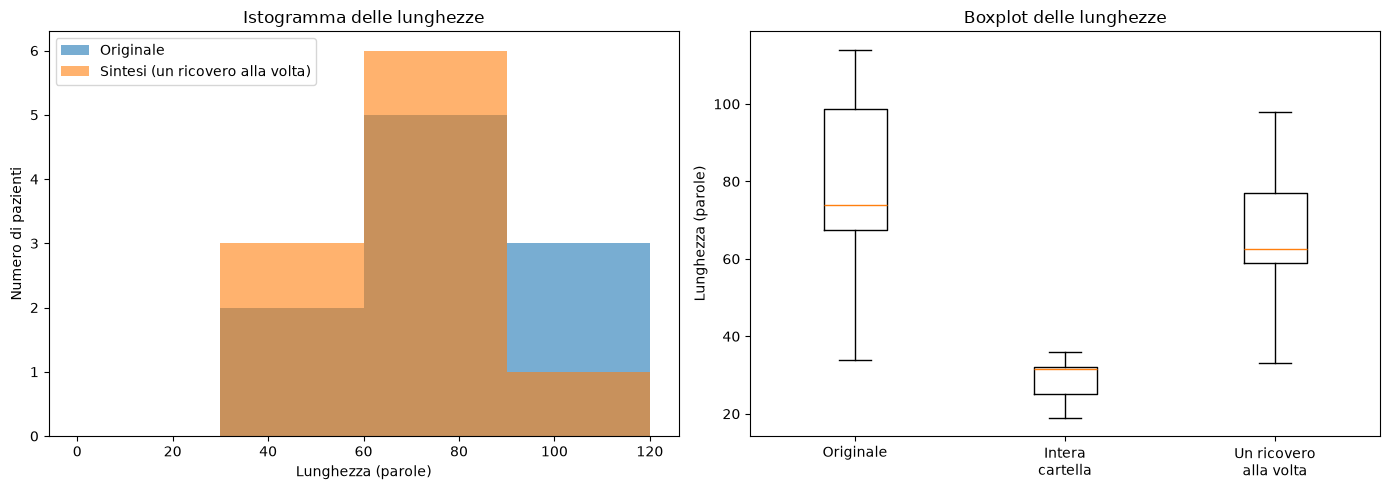

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bins = range(0, int(lengths.values.max()) + 30, 30)
axes[0].hist(lengths["Originale"], bins=bins, alpha=0.6, label="Originale")
axes[0].hist(lengths["Sintesi - un ricovero alla volta"], bins=bins, alpha=0.6, label="Sintesi (un ricovero alla volta)")
axes[0].set_xlabel("Lunghezza (parole)")
axes[0].set_ylabel("Numero di pazienti")
axes[0].set_title("Istogramma delle lunghezze")
axes[0].legend()

axes[1].boxplot([lengths[c] for c in lengths.columns], tick_labels=["Originale", "Intera\ncartella", "Un ricovero\nalla volta"])
axes[1].set_ylabel("Lunghezza (parole)")
axes[1].set_title("Boxplot delle lunghezze")

plt.tight_layout()
plt.show()

Con soli 10 pazienti le distribuzioni vanno lette con cautela, ma i numeri qui sopra e i campioni mostrano alcune cose chiare:

- Il riassunto dell'**intera cartella** accorcia molto il testo (in media il 43% dell'originale, 29 parole contro 76), con una distribuzione molto stretta: la lunghezza non dipende più dal numero di ricoveri, perché il modello produce sempre circa lo stesso numero di frasi. È il segno che i ricoveri successivi vengono scartati
- Il riassunto **un ricovero alla volta** (in media l'87% dell'originale) segue la forma della distribuzione originale: cresce con il numero di ricoveri, perché ogni ricovero viene riassunto separatamente
- La compressione è però modesta: su testi già brevi e strutturati BART lavora in modo quasi estrattivo e **omette singole frasi**. Nei campioni qui sopra, per il Paziente 1 sparisce la prognosi del secondo ricovero ("surgery recommended"), per il Paziente 6 la diagnosi del primo ("heart failure"), ed è proprio questo l'unico caso che porta la copertura delle diagnosi al 93% invece del 100%
- Un riassunto più breve non è quindi un riassunto migliore, e uno più lungo non è necessariamente completo: in ambito clinico le omissioni, come quella di una prognosi, sono il rischio principale, e sono visibili solo leggendo i campioni, non dalle sole lunghezze

---
# Confronto tra gli Approcci
---

Riepiloghiamo la copertura delle diagnosi ottenuta con le tre configurazioni provate.

In [12]:
coverage_results = {
    "BART - intera cartella": coverage_full,
    "BART - un ricovero alla volta": coverage_bart
}

for name, coverage in coverage_results.items():
    print(f"{name:<36}{np.mean(coverage):.0%}")

BART - intera cartella              58%
BART - un ricovero alla volta       93%


| Approccio | Modello | Note |
|---|---|---|
| Intera cartella | `facebook/bart-large-cnn` | il modello privilegia il primo ricovero e perde quelli successivi |
| Un ricovero alla volta | `facebook/bart-large-cnn` | Copertura delle diagnosi molto più alta; riassunti più lunghi ma completi |